In [1]:
knitr::opts_chunk$set(
  collapse = TRUE,
  comment = "#>",
  eval = FALSE
)

# Introduction

This vignette demonstrates how to use the SArf package for spatial
autoregressive random forest analysis from start to finish.

# Installation

## One-Time Setup

In [2]:
# Install development tools
# install.packages("devtools")
# install.packages("roxygen2")

# Install SArf dependencies
# install.packages(c(
#   "ranger", "sf", "spdep", "spatialreg", "blockCV", "ALEPlot",
#   "ggplot2", "dplyr", "tidyr", "leaflet", "htmltools"
# ))

# Install SArf from GitHub
devtools::install_github("kcredit/SArf", force = TRUE)

# Or from local directory
# Set working directory to your package
setwd("~/Dropbox/Packages/SArf/SArf/")
devtools::document()
devtools::install()

# IMPORTANT: Restart R session after installation!

Warning message:
“`install_github()` was deprecated in devtools 2.5.0.
ℹ Please use pak::pak("user/repo") instead.”



listenv (0.10.1 -> 1.0.0) [CRAN]


Installing 1 packages: listenv




The downloaded binary packages are in
	/var/folders/54/0j082m5x2mxcc2wcpp2_glsc0000gn/T//RtmpORBIz8/downloaded_packages
── R CMD build ─────────────────────────────────────────────────────────────────
✔  checking for file ‘/private/var/folders/54/0j082m5x2mxcc2wcpp2_glsc0000gn/T/RtmpORBIz8/remotes13a0a55f0f2a9/kcredit-SArf-2152794/DESCRIPTION’
─  preparing ‘SArf’:
✔  checking DESCRIPTION meta-information
─  checking for LF line-endings in source and make files and shell scripts (459ms)
─  checking for empty or unneeded directories
   Omitted ‘LazyData’ from DESCRIPTION
─  building ‘SArf_0.1.0.tar.gz’
   


ℹ Updating SArf documentation
ℹ Loading SArf
✖ data.R:46: Block must have a @name.
ℹ Either document an existing object or manually specify with @name


── pak::local_install_deps() ───────────────────────────────────────────────────



✔ Updated metadata database: 6.52 MB in 9 files.


ℹ Updating metadata database
✔ Updating metadata database ... done


 

→ Package library at /Library/Frameworks/R.framework/Versions/4.6-x86_64/Resources/library.

→ Will download 1 package with unknown size.

ℹ No downloads are needed

✔ 114 deps: kept 114 [23.3s]



── R CMD build ─────────────────────────────────────────────────────────────────
✔  checking for file ‘/Users/kevincredit/Library/CloudStorage/Dropbox/Packages/SArf/SArf/DESCRIPTION’ (343ms)
─  preparing ‘SArf’: (570ms)
✔  checking DESCRIPTION meta-information
─  checking for LF line-endings in source and make files and shell scripts (606ms)
─  checking for empty or unneeded directories
   Removed empty directory ‘SArf/data-raw’
   Removed empty directory ‘SArf/tests/testthat’
   Removed empty directory ‘SArf/tests’
   Omitted ‘LazyData’ from DESCRIPTION
─  building ‘SArf_0.1.0.tar.gz’
   
── R CMD INSTALL ───────────────────────────────────────────────────────────────
Running /Library/Frameworks/R.framework/Resources/bin/R CMD INSTALL \
  /var/folders/54/0j082m5x2mxcc2wcpp2_glsc0000gn/T//RtmpORBIz8/SArf_0.1.0.tar.gz \
  --install-tests 
* installing to library ‘/Library/Frameworks/R.framework/Versions/4.6-x86_64/Resources/library’
* installing *source* package ‘SArf’ ...
** this is pa

# Load Libraries

In [3]:
library(sf)
library(dplyr)
library(SArf)

# Note: Only load these three to avoid conflicts!

Linking to GEOS 3.14.1, GDAL 3.8.5, PROJ 9.5.1; sf_use_s2() is TRUE


Attaching package: ‘dplyr’


The following objects are masked from ‘package:stats’:

    filter, lag


The following objects are masked from ‘package:base’:

    intersect, setdiff, setequal, union




# Real Example: Health Rating Index for Dublin

This example uses the full dataset from the Health Rating Index project.

**Project Background:** SArf was developed as part of research analyzing
environmental health burdens and benefits across Dublin, Ireland. The
full project is available at
<https://github.com/kcredit/health-rating-index>

## Load Data

In [4]:
# Load included data
data_path <- system.file("extdata", "model_data.shp", package = "SArf")
data <- st_read(data_path)

# Check the data
cat("Dataset size:", nrow(data), "small areas\n")
summary(data$HRI_gaus_p)

# Variables included:
# - HRI_gaus_p: Health Rating Index (outcome)
# - In22_ED: Deprivation index
# - NoAuto_p: % households without car
# - POPD: Population density
# - log_dist: Log distance to nearest primary or secondary road
# - ov60: % over 60 years old
# - nonIrish: % non-Irish citizens

# Clean the data
data_clean <- data %>%
  # Remove missing outcome
  filter(!is.na(HRI_gaus_p)) %>%
  # Remove missing predictors
  filter(complete.cases(HRI_gaus_p, In22_ED, NoAuto_p, POPD, log_dist, ov60, nonIrish)) %>%
  # Fix invalid geometries
  filter(st_is_valid(.))

# Fix duplicate coordinates (important!)
st_geometry(data_clean) <- st_jitter(st_geometry(data_clean), amount = 0.00001)

# Transform to projected CRS (required for spatial blocking)
data_clean <- st_transform(data_clean, 3857)

# Check data
cat("Cleaned data:", nrow(data_clean), "rows\n")
summary(data_clean$HRI_gaus_p)

cat("Any NAs?", sum(is.na(data_clean$HRI_gaus_p)), "\n")

Reading layer `model_data' from data source 
  `/Library/Frameworks/R.framework/Versions/4.6-x86_64/Resources/library/SArf/extdata/model_data.shp' 
  using driver `ESRI Shapefile'
Simple feature collection with 2407 features and 7 fields
Geometry type: POLYGON
Dimension:     XY
Bounding box:  xmin: 306550.1 ymin: 228979.8 xmax: 325539.4 ymax: 242272.4
Projected CRS: +proj=tmerc +lat_0=53.5 +lon_0=-8 +k=1.000035 +x_0=200000 +y_0=250000 +a=6377340.189 +rf=299.3249646 +units=m +no_defs
Dataset size: 2407 small areas


   Min. 1st Qu.  Median    Mean 3rd Qu.    Max. 
-9.1617 -0.3553  0.1151  0.0000  0.5813  1.8317 

Cleaned data: 2407 rows


   Min. 1st Qu.  Median    Mean 3rd Qu.    Max. 
-9.1617 -0.3553  0.1151  0.0000  0.5813  1.8317 

Any NAs? 0 


## Calculate Parameters

In [5]:
n_rows <- nrow(data_clean)
cat("Dataset size:", n_rows, "rows\n")

# Choose parameters based on size
if (n_rows < 1000) {
  # Small dataset - full analysis
  n_folds <- 5
  n_bootstrap <- 20
  num_trees <- 500
  cat("Using full analysis parameters\n")
  
} else if (n_rows < 3000) {
  # Medium dataset - moderate
  n_folds <- 5
  n_bootstrap <- 10
  num_trees <- 500
  cat("Using moderate analysis parameters\n")
  
} else {
  # Very large - sample first
  cat("Very large dataset. Sampling 3000 rows...\n")
  set.seed(1111)
  data_clean <- slice_sample(data_clean, n = 3000)
  n_folds <- 3
  n_bootstrap <- 5
  num_trees <- 250
}

cat("If your data are very large, you can alternatively (or additionally) increase the block range (rough guides):
    Neighbourhood: 500-1000m
    City: 5000-10000m
    County: 12500-25000m
    Region/Country: 50000-100000m", "\n")


Dataset size: 2407 rows
Using moderate analysis parameters
If your data are very large, you can alternatively (or additionally) increase the block range (rough guides):
    Neighbourhood: 500-1000m
    City: 5000-10000m
    County: 12500-25000m
    Region/Country: 50000-100000m 


## Run Analysis


=== SPATIAL AUTOREGRESSIVE RANDOM FOREST ===

Step 1: Testing for spatial autocorrelation...
  Moran's I: 0.364 
  p-value: < 2.22e-16 
  Result: Significant spatial autocorrelation detected

Step 2: Creating spatial weights matrix...

Step 3: Running spatial cross-validation random forest...
  5 folds × 10 iterations = 50 models
  Dataset size: 2407 observations
  Total models to fit: 50 
  Creating spatial blocks...

  train test
1  1934  473
2  1940  467
3  1835  572
4  1960  447
5  1959  448
  blockCV failed, using k-means...
  Fold sizes:
    Fold 1: 2015 train, 392 test
    Fold 2: 1829 train, 578 test
    Fold 3: 1935 train, 472 test
    Fold 4: 1779 train, 628 test
    Fold 5: 2070 train, 337 test
  Running spatial CV bootstrap...
    Iteration 1 of 10 
    Iteration 5 of 10 
    Iteration 10 of 10 
  Spatial CV Results:
    RMSE: 0.8416 
    R²: 0.2923 
    Moran's I (residuals): 0.2201 ( p = < 2.22e-16 )

Step 4: Comparing to spatial econometric models...

  Note: Large data

This method assumes the response is known - see manual page



    ✓ SEM complete (71.4s)
  Fitting SAC (Spatial Lag + Error)... [May take 2-5 minutes]
    ✓ SAC complete (294s)
  Calculating Moran's I for RF residuals...
    ✓ Moran's I = 0.2201 

  Model Comparison:
         Model   RMSE     R2 Morans_I Morans_pval
      Naive_RF 0.7137 0.5280  -0.0006      0.4566
           OLS 0.8045 0.3526   0.1653      0.0000
           SAR 0.7277 0.4710   0.0136      0.0115
           SEM 0.7233 0.4836  -0.0024      0.6238
           SAC 0.7282 0.4706   0.0000      0.4724
 RF_Spatial_CV 0.8416 0.2923   0.2201      0.0000

  Note: Naive_RF uses simple train-test split with spatial lag calculated from ALL observations.
        RF_Spatial_CV uses spatial cross-validation with within-fold spatial lag calculation.

Step 5: Calculating variable importance with confidence intervals...
  Variable Importance (Top 5):
    spatial_lag: 0.3854 [0.2192, 0.4672]
    ov60: 0.2375 [0.2114, 0.2786]
    log_dist: 0.1916 [0.1376, 0.2199]
    nonIrish: 0.1200 [0.0831, 0.1467]


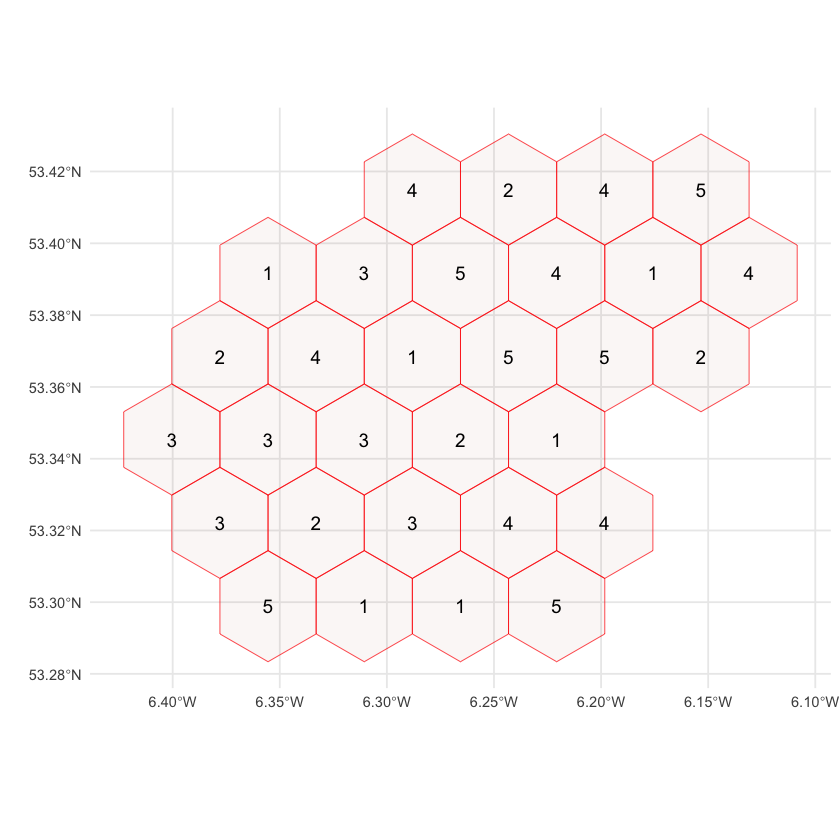

In [6]:
# Run SArf analysis
results <- SArf(
  HRI_gaus_p ~ In22_ED + NoAuto_p + POPD + log_dist + ov60 + nonIrish,
  data = data_clean,
  k_neighbors = 20,             # Number of neighbors for spatial weights
  n_folds = n_folds,            # Spatial CV folds
  n_bootstrap = n_bootstrap,    # Bootstrap iterations
  num_trees = num_trees,        # Trees in random forest
  include_naive_rf = TRUE,      # For comparison with "naive" random forest
  naive_test_fraction = 0.2,
  create_map = TRUE,            # Spatial folds map
  block_range = 5000,           # Size of the spatial blocks in metres
  verbose = TRUE                # Print progress
)

## View Results

Model,RMSE,R2,Morans_I,Morans_pval
<chr>,<dbl>,<dbl>,<dbl>,<dbl>
Naive_RF,0.7137,0.5280,-0.0006,0.4566
OLS,0.8045,0.3526,0.1653,0.0000
SAR,0.7277,0.4710,0.0136,0.0115
SEM,0.7233,0.4836,-0.0024,0.6238
SAC,0.7282,0.4706,0.0000,0.4724
RF_Spatial_CV,0.8416,0.2923,0.2201,0.0000


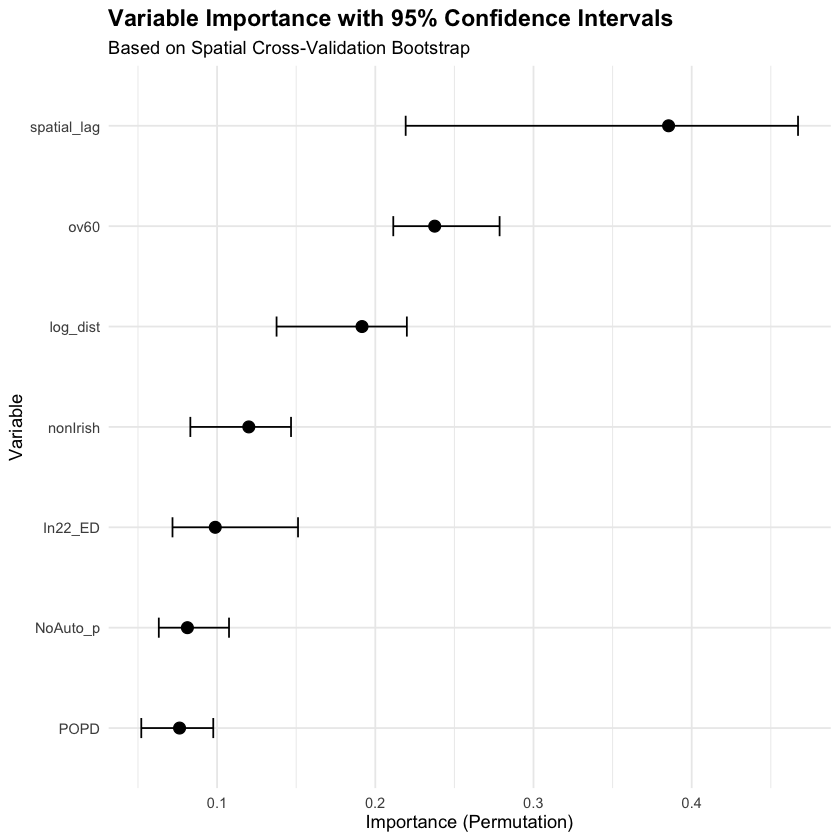


OLS MODEL - FULL RESULTS


Call:
lm(formula = formula, data = model_data)

Residuals:
    Min      1Q  Median      3Q     Max 
-7.5248 -0.3278  0.0846  0.4750  2.4940 

Coefficients:
              Estimate Std. Error t value Pr(>|t|)    
(Intercept)  3.122e-16  1.642e-02   0.000    1.000    
In22_ED      1.392e-01  1.854e-02   7.506 8.55e-14 ***
NoAuto_p     1.414e-01  1.865e-02   7.583 4.78e-14 ***
POPD         1.523e-01  2.038e-02   7.469 1.13e-13 ***
log_dist     3.654e-01  1.753e-02  20.841  < 2e-16 ***
ov60        -3.268e-01  2.212e-02 -14.773  < 2e-16 ***
nonIrish     1.710e-02  2.471e-02   0.692    0.489    
---
Signif. codes:  0 ‘***’ 0.001 ‘**’ 0.01 ‘*’ 0.05 ‘.’ 0.1 ‘ ’ 1

Residual standard error: 0.8056 on 2400 degrees of freedom
Multiple R-squared:  0.3526,	Adjusted R-squared:  0.3509 
F-statistic: 217.8 on 6 and 2400 DF,  p-value: < 2.2e-16



SAR MODEL - FULL RESULTS


Call:
spatialreg::lagsarlm(formula = formula, data = model_data, listw = spatial_weights, 
    zero.poli

HTML widgets cannot be represented in plain text (need html)

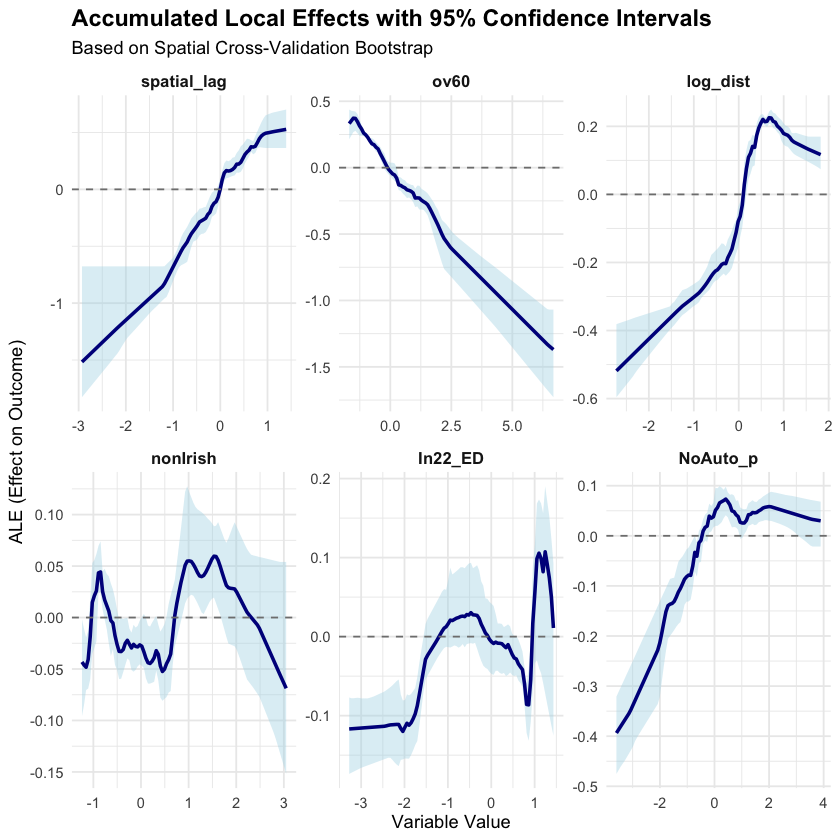

In [7]:
# Model comparison
results$model_comparison

# Variable importance
results$importance_plot

# ALE plots
results$ale_plots

# Full sptial econometric model results
show_models(results)

# Interactive map
results$leaflet_map

## Save Outputs

In [8]:
# Create output directory
dir.create("output", showWarnings = FALSE)

# Save plots
ggsave("output/moran_plot.png", results$moran_plot, width = 6, height = 5)
ggsave("output/importance_plot.png", results$importance_plot, width = 8, height = 6)
ggsave("output/ale_plots.png", results$ale_plots, width = 10, height = 8)

# Save tables
write.csv(results$model_comparison, "output/model_comparison.csv", row.names = FALSE)
write.csv(results$variable_importance, "output/variable_importance.csv", row.names = FALSE)
write.csv(results$ale_results, "output/ale_data.csv", row.names = FALSE)

# Save map
# library(htmlwidgets)
# saveWidget(results$leaflet_map, "output/results_map.html")

cat("All outputs saved to output/ directory\n")

ERROR: Error in ggsave("output/moran_plot.png", results$moran_plot, width = 6, : could not find function "ggsave"


## Verify Results

In [9]:
# =================================================================
# VERIFICATION CODE TO ENSURE SPATIAL LAGS ARE CALCULATED CORRECTLY
# =================================================================

# Extract spatial_weights from results
spatial_weights <- results$spatial_weights

# ========================================
# 1. Get fold structure for verification
# ========================================
fold_1 <- results$spatial_cv_results$predictions %>%
  filter(fold == 1, iteration == 1)

test_idx <- fold_1 %>% filter(in_training == FALSE) %>% pull(row_id)
train_idx <- fold_1 %>% filter(in_training == TRUE) %>% pull(row_id)

cat("Fold 1, Iteration 1:\n")
cat("Training observations:", length(train_idx), "\n")
cat("Test observations:", length(test_idx), "\n\n")

# ========================================
# 2. Get coordinates and extract k
# ========================================
all_coords <- st_coordinates(st_centroid(st_geometry(data_clean)))
train_coords <- all_coords[train_idx, , drop = FALSE]

# Extract k from spatial_weights
k_neighbors <- round(mean(sapply(spatial_weights$neighbours, length)))
cat("k (number of neighbors):", k_neighbors, "\n\n")

# ========================================
# 3. For EACH test observation, verify neighbors are ALL from training set
# ========================================
cat("=== Verifying Spatial Lag Calculation ===\n\n")

# Get response variable name from results
response_var <- all.vars(results$formula)[1]

verification_results <- data.frame(
  test_obs = test_idx,
  stored_lag = numeric(length(test_idx)),
  calculated_lag = numeric(length(test_idx)),
  match = logical(length(test_idx)),
  n_neighbors = numeric(length(test_idx)),
  any_from_test = logical(length(test_idx))
)

for (i in 1:length(test_idx)) {
  obs <- test_idx[i]
  
  # Get stored spatial lag from predictions
  stored_lag <- fold_1 %>% filter(row_id == obs) %>% pull(spatial_lag)
  
  # Calculate what spatial lag SHOULD be (using training neighbors only)
  obs_coord <- all_coords[obs, , drop = FALSE]
  
  # Find distances to ALL training observations
  dists <- sqrt(rowSums(sweep(train_coords, 2, obs_coord, "-")^2))
  
  # Find k nearest TRAINING neighbors
  k_to_use <- min(k_neighbors, length(dists))
  nearest_indices <- order(dists)[1:k_to_use]
  neighbor_rows <- train_idx[nearest_indices]
  
  # Calculate spatial lag with W-style weights (simple mean)
  calculated_lag <- mean(data_clean[[response_var]][neighbor_rows])
  
  # Check if any neighbors are from test set (should be NONE!)
  any_from_test <- any(neighbor_rows %in% test_idx)
  
  # Store results
  verification_results$stored_lag[i] <- stored_lag
  verification_results$calculated_lag[i] <- calculated_lag
  verification_results$match[i] <- abs(stored_lag - calculated_lag) < 0.001
  verification_results$n_neighbors[i] <- k_to_use
  verification_results$any_from_test[i] <- any_from_test
}

# ========================================
# 4. Summary Statistics
# ========================================
cat("=== VERIFICATION RESULTS ===\n\n")

cat("Total test observations checked:", nrow(verification_results), "\n")
cat("Stored values match calculated:", sum(verification_results$match), "/", nrow(verification_results), "\n")
cat("Observations with neighbors from test set:", sum(verification_results$any_from_test), "\n\n")

if (sum(verification_results$any_from_test) > 0) {
  cat("❌ PROBLEM: Some test observations have neighbors from test set!\n")
  cat("This indicates data leakage.\n\n")
  
  # Show which observations have test neighbors
  problem_obs <- verification_results %>% filter(any_from_test == TRUE)
  cat("Problem observations:\n")
  print(problem_obs %>% select(test_obs, any_from_test))
  
} else {
  cat("✅ SUCCESS: NO test observations have neighbors from test set!\n")
  cat("All spatial lags use only training neighbors.\n\n")
}

if (all(verification_results$match)) {
  cat("✅ SUCCESS: All stored spatial_lag values match manual calculations!\n")
  cat("The order() bug is fixed.\n\n")
} else {
  cat("❌ PROBLEM: Some stored values don't match calculations!\n")
  cat("Number of mismatches:", sum(!verification_results$match), "\n\n")
  
  # Show mismatches
  mismatches <- verification_results %>% filter(match == FALSE)
  cat("Mismatched observations (first 10):\n")
  print(head(mismatches %>% select(test_obs, stored_lag, calculated_lag), 10))
}

# ========================================
# 5. Detailed Check for Random Sample
# ========================================
cat("\n=== DETAILED CHECK: 5 Random Test Observations ===\n\n")

sample_obs <- sample(test_idx, min(5, length(test_idx)))

for (obs in sample_obs) {
  cat("Observation:", obs, "\n")
  
  # Get stored value
  stored <- fold_1 %>% filter(row_id == obs) %>% pull(spatial_lag)
  
  # Calculate manually
  obs_coord <- all_coords[obs, , drop = FALSE]
  dists <- sqrt(rowSums(sweep(train_coords, 2, obs_coord, "-")^2))
  k_to_use <- min(k_neighbors, length(dists))
  nearest_indices <- order(dists)[1:k_to_use]
  neighbor_rows <- train_idx[nearest_indices]
  calculated <- mean(data[[response_var]][neighbor_rows])
  
  cat("  Stored spatial_lag:    ", round(stored, 6), "\n")
  cat("  Calculated spatial_lag:", round(calculated, 6), "\n")
  cat("  Match:                 ", abs(stored - calculated) < 0.001, "\n")
  cat("  Number of neighbors:   ", k_to_use, "\n")
  cat("  All from training set: ", all(neighbor_rows %in% train_idx), "\n")
  cat("  Any from test set:     ", any(neighbor_rows %in% test_idx), "\n")
  
  # Show neighbor IDs
  cat("  Neighbor row IDs:      ", paste(head(neighbor_rows, 10), collapse = ", "))
  if (k_to_use > 10) cat(", ...")
  cat("\n\n")
}

# ========================================
# 6. Final Summary
# ========================================
cat("=== FINAL ASSESSMENT ===\n\n")

if (sum(verification_results$any_from_test) == 0 && all(verification_results$match)) {
  cat("✅✅✅ PERFECT! ✅✅✅\n")
  cat("1. NO data leakage (all neighbors from training set)\n")
  cat("2. Storage is correct (stored values match calculations)\n")
  cat("3. Your spatial CV implementation is working correctly!\n")
} else {
  if (sum(verification_results$any_from_test) > 0) {
    cat("❌ Data leakage detected\n")
  }
  if (!all(verification_results$match)) {
    cat("❌ Storage bug detected\n")
  }
  cat("\nSee details above for specific issues.\n")
}


Fold 1, Iteration 1:
Training observations: 2015 
Test observations: 392 

k (number of neighbors): 20 

=== Verifying Spatial Lag Calculation ===

=== VERIFICATION RESULTS ===

Total test observations checked: 392 
Stored values match calculated: 392 / 392 
Observations with neighbors from test set: 0 

✅ SUCCESS: NO test observations have neighbors from test set!
All spatial lags use only training neighbors.

✅ SUCCESS: All stored spatial_lag values match manual calculations!
The order() bug is fixed.


=== DETAILED CHECK: 5 Random Test Observations ===

Observation: 1668 
  Stored spatial_lag:     -0.209563 
  Calculated spatial_lag: -0.209563 
  Match:                  TRUE 
  Number of neighbors:    20 
  All from training set:  TRUE 
  Any from test set:      FALSE 
  Neighbor row IDs:       693, 1900, 1906, 2301, 355, 2052, 1896, 1998, 2053, 2295, ...

Observation: 1666 
  Stored spatial_lag:     -1.055727 
  Calculated spatial_lag: -1.055727 
  Match:                  TRUE 
  N

## Full Project

For the complete analysis and reproducible code: - **GitHub:**
<https://github.com/kcredit/health-rating-index> - **Publication:**
Credit et al. (2026), Wellbeing, Space and Society - **DOI:**
10.1016/j.wss.2026.100356

# Interpretation Guide

## Model Comparison

-   **RMSE**: Lower is better
-   **R²**: Higher is better (0-1 scale)
-   **Moran's I**: Close to 0 indicates no spatial autocorrelation in
    residuals
-   **Typically**: RF \> spatial models for R², spatial models remove
    autocorrelation

## Variable Importance

-   High mean = strong predictor
-   Narrow CI = consistent across folds
-   spatial_lag often important (neighborhood effects)

## ALE Plots

-   Positive slope = positive effect
-   Negative slope = negative effect
-   Curves = non-linear relationships
-   Confidence bands = uncertainty

# Tips and Best Practices

**Dataset Size:** - \< 1000: Full parameters - 1000-3000: Moderate
parameters - 3000: Sample or reduce parameters

**Block Range:** - Too small → "same area" error - Too large → empty
folds - Use a literal value in metres appropriate to your study area (e.g., 5000 for a city)

**Performance:** - 500 obs: \~5 min - 1000 obs: \~10 min - 2000 obs:
\~20 min - 3000 obs: \~45 min

**Avoid Conflicts:** - Only load: SArf, sf, dplyr - Don't load ranger,
spdep, etc. directly

# Troubleshooting

**"All points from same area"** - Increase block_range - Reduce n_folds

**Moran's I shows NA** - Check for missing values - Ensure no duplicate
coordinates

**Very slow** - Sample to 2000-3000 rows - Reduce n_bootstrap to 3-5

# Citation

```         
Credit, K. (2026). SArf: Spatial Autoregressive
Random Forest. https://github.com/kcredit/SArf

Credit, K., Kaur, D., & Eccles, E. (2026). Analysing urban inequalities
in environment and health at the neighbourhood scale in Dublin through a
new open-access 'Health Rating Index'. Wellbeing, Space and Society, 10,
100356. DOI: 10.1016/j.wss.2026.100356
```

# Session Info

In [ ]:
sessionInfo()